# Chapter 61: Endogenous Growth, Ideas, Human Capital, and Innovation

This notebook reruns four worked examples from the chapter: a research boost under semi-endogenous growth, creative destruction on a quality ladder, weakest link (O-ring) teams, and saving in an AK economy. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def semi_endogenous(delta, L_A, A, lam, phi, n):
    """semi-endogenous-growth (chapter 61): g_A = delta L_A^lam / A^(1 - phi) at the current A,
    balanced g* = lam n / (1 - phi), flow A_dot = g_A A, and the long-run level multiple of
    A per doubling of L_A, 2^(lam / (1 - phi)).

    Book: delta 0.025, L_A 144, A 8,100, lam 1, phi 0.5, n 0.02 gives g_A 0.04, A_dot 324,
    g* 0.04; L_A 288 gives g_A 0.08, A_dot 648; level multiple 4.
    """
    g = delta * L_A ** lam / A ** (1.0 - phi)
    return {"g_A": g, "A_dot": g * A, "g_star": lam * n / (1.0 - phi),
            "level_multiple_per_doubling": 2.0 ** (lam / (1.0 - phi))}


def quality_ladder(lam, gamma, profit, r):
    """schumpeterian-quality-ladder-growth (chapter 61): expected log growth g = lam ln(gamma)
    and leader value V = profit / (r + lam).

    Book: lam 0.10, gamma 1.20, profit 15, r 0.05 gives g 0.018232, V 100; lam 0.15 gives
    g 0.027348, V 75.
    """
    return {"g": lam * math.log(gamma), "V": profit / (r + lam)}


def ak_growth(s, A, delta, n):
    """ak-endogenous-growth-mechanism (chapter 61): per-person growth g_y = s A - delta - n.

    Book: s 0.24, A 0.25, delta 0.035, n 0.005 gives 0.02; s 0.30 gives 0.035.
    """
    return s * A - delta - n


def exp_path(y0, g, T, discrete=False):
    """Level after T periods at growth g: y0 e^(g T), or y0 (1 + g)^T when discrete is True.

    ak-endogenous-growth-mechanism (chapter 61): 50 e^(0.02 x 10) = 61.07 and
    50 e^(0.035 x 10) = 70.95.
    """
    return y0 * (1.0 + g) ** T if discrete else y0 * math.exp(g * T)


def o_ring(B, qualities):
    """o-ring-production-function (chapter 61): team output B x product of worker qualities.

    Book (B n = 120): 120(0.90)(0.60) = 64.8; 120(0.90)^2 = 97.2; 120(0.60)^2 = 43.2.
    """
    out = float(B)
    for q in qualities:
        out *= q
    return out


plt.rcParams.update(HOUSE_RC)


growth = SimpleNamespace(semi_endogenous=semi_endogenous, quality_ladder=quality_ladder, ak_growth=ak_growth, exp_path=exp_path)


production = SimpleNamespace(o_ring=o_ring)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'semi-endogenous-growth': {'delta': 0.025,
                            'lam': 1,
                            'phi': 0.5,
                            'L_A': 144,
                            'A': 8100,
                            'n': 0.02,
                            'g_A': 0.04,
                            'A_dot': 324,
                            'g_star': 0.04,
                            'L_A_2': 288,
                            'g_A_2': 0.08,
                            'A_dot_2': 648,
                            'level_multiple': 4},
 'schumpeterian-quality-ladder-growth': {'A0': 100,
                                         'gamma': 1.2,
                                         'lam': 0.1,
                                         'profit': 15,
                                         'r': 0.05,
                                         'g': 0.018232,
                                         'V': 100,
                                         'lam_2': 0.15,
                                         'g_2': 0.027348,
                                         'V_2': 75,
                                         'A1': 120},
 'o-ring-production-function': {'Bn': 120,
                                'h': 0.9,
                                'l': 0.6,
                                'mixed_team': 64.8,
                                'mixed_total': 129.6,
                                'high_team': 97.2,
                                'low_team': 43.2,
                                'sorted_total': 140.4,
                                'sorting_gain': 10.8,
                                'train': 0.15,
                                'train_gain_low': 10.8,
                                'train_gain_high': 16.2,
                                'train_diff': 5.4},
 'ak-endogenous-growth-mechanism': {'A': 0.25,
                                    's': 0.24,
                                    'delta': 0.035,
                                    'n': 0.005,
                                    'k0': 200,
                                    'y0': 50,
                                    'g': 0.02,
                                    's_2': 0.3,
                                    'g_2': 0.035,
                                    'y10': 61.07,
                                    'y10_2': 70.95,
                                    'gap': 9.88,
                                    'net_acc': 4,
                                    'net_acc_2': 7},
 'constructed': {'semi-endogenous-growth': {'mult': [3], 'phi': [0.25, 0.75]},
                 'schumpeterian-quality-ladder-growth': {'lam': [0.05, 0.2], 'gamma': [1.1, 1.3]},
                 'o-ring-production-function': {'l': [0.45, 0.75]},
                 'ak-endogenous-growth-mechanism': {'s': [0.18], 'T': [20, 40]}}}


def semi_path(mult, phi, years=150, dt=0.05):
    """Yearly g_A after research labor jumps by ``mult`` at year 0 from a balanced path.

    delta is set so the starting point is on the balanced path (book: 0.04 x 90 / 144 = 0.025).
    Returns (years, g_A by year, delta).
    """
    b = BV["semi-endogenous-growth"]
    g_star = b["lam"] * b["n"] / (1 - phi)
    delta = g_star * b["A"] ** (1 - phi) / b["L_A"] ** b["lam"]
    A, L = float(b["A"]), mult * b["L_A"]
    steps = int(round(1 / dt))
    out = []
    for yr in range(years + 1):
        g = growth.semi_endogenous(delta, L, A, b["lam"], phi, b["n"])["g_A"]
        out.append(g)
        for _ in range(steps):
            g = growth.semi_endogenous(delta, L, A, b["lam"], phi, b["n"])["g_A"]
            A *= math.exp(g * dt)
            L *= math.exp(b["n"] * dt)
    return np.arange(years + 1), np.array(out), delta


def semi_picture(mult=2, phi=0.5):
    b = BV["semi-endogenous-growth"]
    yrs, gs, delta = semi_path(mult, phi)
    r = growth.semi_endogenous(delta, mult * b["L_A"], b["A"], b["lam"], phi, b["n"])
    g_star, g0 = r["g_star"], r["g_A"]
    level = mult ** (b["lam"] / (1 - phi))
    fig, ax = new_figure()
    ax.plot(yrs, 100 * gs, color=PALETTE["teal"], linewidth=2.2)
    hline(ax, 100 * g_star, f"balanced growth {pct(g_star, 2)}", col="navy", va="top")
    mark(ax, 0, 100 * g0, f"impact {pct(g0, 2)}", col="terracotta", dx=8, dy=4)
    ax.set_xlim(-3, 150)
    ax.set_ylim(0, max(100 * g0, 100 * g_star) * 1.25)
    ax.set_xlabel("Years after the change")
    ax.set_ylabel("Technology growth g_A (%)")
    ax.text(0.97, 0.80, f"long-run level of A: x {num(level)}", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["gold"])
    L_new = mult * b["L_A"]
    root = b["A"] ** (1 - phi)
    rd, dd = (4, 7) if phi > 0.6 else (2, 6)  # enough digits that the shown line multiplies out
    metrics = {"Research labor L_A": num(L_new, 0), "delta": num(delta, dd).rstrip("0").rstrip("."),
               "Impact g_A": pct(g0, 2), "Balanced g*": pct(g_star, 2), "Long-run level multiple of A": num(level)}
    if mult == 1:
        verdict = "With no change in research labor, growth stays at the balanced rate and the level multiple is 1."
    else:
        verdict = (f"Growth jumps to {pct(g0, 2)} and then decays back to {pct(g_star, 2)}: the {num(mult, 0)}-fold "
                   f"research effort buys a permanently higher level, not faster long-run growth.")
    interp = (f"g* = 1 x 0.02 / (1 - {num(phi)}) = {num(g_star, 4)}. With delta = {num(delta, dd)} the old path is "
              f"balanced, and at A = 8,100 the impact rate is {num(delta, dd)} x {num(L_new, 0)} / "
              f"{num(root, rd)} = {num(g0, 4)}. The level multiple is {num(mult, 0)}^(1 / {num(1 - phi)}) = "
              f"{num(level)}. {verdict}")
    steps = [f"g* = lambda n / (1 - phi) = 0.02 / {num(1 - phi)} = {num(g_star, 4)}",
             f"delta = g* x 8,100^{num(1 - phi)} / 144 = {num(g_star, 6)} x {num(root, rd)} / 144 = "
             f"{num(delta, dd)}",
             f"Impact g_A = {num(delta, dd)} x {num(L_new, 0)} / {num(root, rd)} = {num(g0, 4)}",
             f"Level multiple = {num(mult, 0)}^(1 / {num(1 - phi)}) = {num(level)}"]
    alt = (f"Technology growth over 150 years after research labor is multiplied by {num(mult, 0)} with phi = "
           f"{num(phi)}. Growth starts at {pct(g0, 2)} and returns toward the balanced rate {pct(g_star, 2)}; the "
           f"long-run level of A is {num(level)} times the old path.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ladder_picture(lam=0.10, gamma=1.20):
    b = BV["schumpeterian-quality-ladder-growth"]
    r = growth.quality_ladder(lam, gamma, b["profit"], b["r"])
    lams = np.linspace(0.02, 0.25, 100)
    gs = [100 * growth.quality_ladder(x, gamma, b["profit"], b["r"])["g"] for x in lams]
    vs = [growth.quality_ladder(x, gamma, b["profit"], b["r"])["V"] for x in lams]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot(lams, gs, color=PALETTE["teal"], linewidth=2.2)
    mark(ax1, lam, 100 * r["g"], f"{num(100 * r['g'], 3)}%", col="teal", dx=-8, dy=6, ha="right")
    ax1.set_xlabel("Innovation arrival rate lambda")
    ax1.set_ylabel("Expected growth (%)")
    ax1.set_ylim(0, 7)
    ax2.plot(lams, vs, color=PALETTE["terracotta"], linewidth=2.2)
    mark(ax2, lam, r["V"], f"V = {num(r['V'])}", col="terracotta", dx=8, dy=6)
    ax2.set_xlabel("Innovation arrival rate lambda")
    ax2.set_ylabel("Leader value V")
    ax2.set_ylim(0, 230)
    lng = math.log(gamma)
    metrics = {"ln(gamma)": num(lng, 6), "Expected growth": f"{num(100 * r['g'], 3)}%",
               "Leader value V": num(r["V"]), "Change in V vs lambda 0.10": f"{'+' if r['V'] > 100 + 1e-9 else ''}{num(r['V'] - 100)}"}
    interp = (f"Growth = {num(lam)} x ln({num(gamma)}) = {num(lam)} x {num(lng, 6)} = {num(r['g'], 6)}, or "
              f"{num(100 * r['g'], 3)} percent a year. The leader's value is 15 / (0.05 + {num(lam)}) = "
              f"{num(r['V'])}. Faster entry raises growth and shortens each leadership spell; the quality step "
              f"changes growth but not V.")
    steps = [f"ln({num(gamma)}) = {num(lng, 6)}",
             f"g = {num(lam)} x {num(lng, 6)} = {num(r['g'], 6)}",
             f"r + lambda = 0.05 + {num(lam)} = {num(0.05 + lam)}",
             f"V = 15 / {num(0.05 + lam)} = {num(r['V'])}"]
    alt = (f"Left: expected growth rises with the arrival rate; at lambda {num(lam)} and step {num(gamma)} it is "
           f"{num(100 * r['g'], 3)} percent. Right: the leader's value falls with the arrival rate, to {num(r['V'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def oring_picture(l=0.60, match="sorted"):
    b = BV["o-ring-production-function"]
    B, h, t = b["Bn"], b["h"], b["train"]
    mixed = production.o_ring(B, [h, l])
    hi, lo = production.o_ring(B, [h, h]), production.o_ring(B, [l, l])
    mixed_total, sorted_total = 2 * mixed, hi + lo
    gain = sorted_total - mixed_total
    tr_low, tr_high = B * l * t, B * h * t
    teams = [mixed, mixed] if match == "mixed" else [hi, lo]
    names = ["Team 1", "Team 2", "Total"]
    vals = teams + [sum(teams)]
    fig, ax = new_figure()
    cols = [PALETTE["teal"], PALETTE["navy"], PALETTE["gold"]]
    ax.bar(range(3), vals, color=cols, width=0.6)
    ax.set_xticks(range(3), names)
    for x, v in enumerate(vals):
        ax.annotate(num(v, 1), (x, v), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, bbox=dict(facecolor="white", edgecolor="none", pad=1.0))
    pairs = [f"{num(h)} and {num(l)}", f"{num(h)} and {num(l)}"] if match == "mixed" else \
        [f"{num(h)} and {num(h)}", f"{num(l)} and {num(l)}"]
    for x, p in enumerate(pairs):
        ax.annotate(p, (x, 3), ha="center", va="bottom", fontsize=10.5, color="white")
    other = sorted_total if match == "mixed" else mixed_total
    ax.axhline(other, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4)
    ax.text(0.02, 0.97, f"dashed line: {'sorted' if match == 'mixed' else 'mixed'} total {num(other, 1)}",
            transform=ax.transAxes, ha="left", va="top", fontsize=10.5, color=PALETTE["grey"])
    ax.set_ylim(0, 200)
    ax.set_xlim(-0.6, 2.6)
    ax.set_ylabel("Output")
    ax.set_xlabel(f"{'Mixed' if match == 'mixed' else 'Sorted'} teams")
    metrics = {"Mixed total": num(mixed_total, 1), "Sorted total": num(sorted_total, 1),
               "Sorting gain": num(gain, 1), "Training gain beside 0.90": num(tr_high, 1),
               f"Training gain beside {num(l)}": num(tr_low, 1)}
    interp = (f"Mixed: 2 x 120 x 0.90 x {num(l)} = {num(mixed_total, 1)}. Sorted: 120 x 0.90^2 + 120 x "
              f"{num(l)}^2 = {num(hi, 1)} + {num(lo, 1)} = {num(sorted_total, 1)}. The gain from sorting is "
              f"120 x ({num(h)} - {num(l)})^2 = {num(gain, 1)} with no change in any skill. Raising a "
              f"{num(l)} worker by 0.15 adds {num(tr_high, 1)} beside a 0.90 partner and {num(tr_low, 1)} beside a "
              f"{num(l)} partner.")
    steps = [f"Mixed team = 120 x 0.90 x {num(l)} = {num(mixed, 1)}; two teams = {num(mixed_total, 1)}",
             f"Sorted = {num(hi, 1)} + {num(lo, 1)} = {num(sorted_total, 1)}",
             f"Gain = {num(sorted_total, 1)} - {num(mixed_total, 1)} = {num(gain, 1)} = 120 x "
             f"{num(h - l)}^2",
             f"Training: 120 x 0.90 x 0.15 = {num(tr_high, 1)}; 120 x {num(l)} x 0.15 = {num(tr_low, 1)}"]
    alt = (f"Bars for two {'mixed' if match == 'mixed' else 'sorted'} teams and their total, "
           f"{num(sum(teams), 1)}, with a dashed line at the other arrangement's total {num(other, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ak_picture(s=0.30, years=10):
    T = years
    b = BV["ak-endogenous-growth-mechanism"]
    A, d, n, y0 = b["A"], b["delta"], b["n"], b["y0"]
    g0 = growth.ak_growth(b["s"], A, d, n)
    g1 = growth.ak_growth(s, A, d, n)
    yb, yc = growth.exp_path(y0, g0, T), growth.exp_path(y0, g1, T)
    ts = np.linspace(0, T, 200)
    pb = [growth.exp_path(y0, g0, t) for t in ts]
    pc = [growth.exp_path(y0, g1, t) for t in ts]
    fig, ax = new_figure()
    ax.plot(ts, pb, color=PALETTE["navy"], linewidth=2, label="baseline s = 0.24")
    ax.plot(ts, pc, color=PALETTE["teal"], linewidth=2.2, label=f"chosen s = {num(s)}")
    ax.fill_between(ts, pb, pc, color=PALETTE["gold"], alpha=0.18)
    ax.legend(loc="upper left", frameon=False)
    mark(ax, T, yc, num(yc), col="teal", dx=-8, dy=6 if yc >= yb else -6, ha="right",
         va="bottom" if yc >= yb else "top")
    if abs(yc - yb) > 1e-9:
        mark(ax, T, yb, num(yb), col="navy", dx=-8, dy=-6 if yc > yb else 6, ha="right",
             va="top" if yc > yb else "bottom")
    ax.set_xlim(0, T * 1.02)
    ax.set_ylim(min(min(pb), min(pc)) * 0.92, max(max(pb), max(pc)) * 1.1)
    ax.set_xlabel("Years")
    ax.set_ylabel("Output per person y")
    gap = yc - yb
    inv, net = s * y0, s * y0 - d * 200 - n * 200
    metrics = {"Growth at chosen s": pct(g1, 1), "Baseline growth": pct(g0, 1), f"y at year {T}": num(yc),
               "Baseline y": num(yb), "Gap": num(gap), "Net accumulation at k = 200": num(net)}
    if abs(gap) < 1e-9:
        verdict = "The chosen saving rate is the baseline, so the two paths coincide."
    elif gap > 0:
        verdict = "The gap keeps widening because the growth difference never shrinks in the AK model."
    else:
        verdict = "Lower saving puts the path permanently below the baseline, and the shortfall widens."
    interp = (f"g = {num(s)} x 0.25 - 0.035 - 0.005 = {num(g1, 4)}. Starting from y0 = 50, y at year {T} is "
              f"50 e^({num(g1, 4)} x {T}) = {num(yc)} against a baseline 50 e^(0.02 x {T}) = {num(yb)}, a gap of "
              f"{num(gap)}. At k = 200 net accumulation is {num(inv)} - 7 - 1 = {num(net)}. {verdict}")
    steps = [f"g = {num(s)} x 0.25 - 0.035 - 0.005 = {num(g1, 4)}",
             f"Investment at k = 200: {num(s)} x 50 = {num(inv)}; net = {num(inv)} - 7 - 1 = {num(net)}",
             f"y_T = 50 e^({num(g1 * T, 4)}) = {num(yc)}",
             f"Baseline y_T = 50 e^({num(g0 * T, 4)}) = {num(yb)}",
             f"Gap = {num(yc)} - {num(yb)} = {num(gap)}"]
    alt = (f"Output paths from 50 over {T} years: baseline saving 0.24 grows at 2.0 percent to {num(yb)}; saving "
           f"{num(s)} grows at {pct(g1, 1)} to {num(yc)}. The shaded gap is {num(gap)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Semi-endogenous growth: more researchers, same long-run growth

Research productivity $\delta=0.025$, $\lambda=1$, $\phi=0.5$, research labor $L_A=144$ growing at $n=2\%$, knowledge stock $A=8{,}100$.

$$g_A=\frac{0.025(144)}{\sqrt{8{,}100}}=\frac{3.6}{90}=0.04, \qquad g_A^*=\frac{1(0.02)}{1-0.5}=0.04$$

Doubling research labor to 288:

$$g_A'=\frac{0.025(288)}{90}=0.08, \qquad 2^{\lambda/(1-\phi)}=2^{1/0.5}=4$$

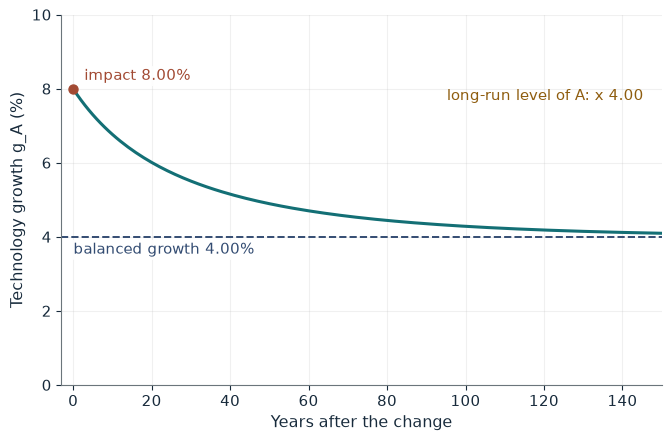

Research labor L_A            288
delta                         0.025
Impact g_A                    8.00%
Balanced g*                   4.00%
Long-run level multiple of A  4.00

Worked steps:
  1. g* = lambda n / (1 - phi) = 0.02 / 0.50 = 0.0400
  2. delta = g* x 8,100^0.50 / 144 = 0.040000 x 90.00 / 144 = 0.025000
  3. Impact g_A = 0.025000 x 288 / 90.00 = 0.0800
  4. Level multiple = 2^(1 / 0.50) = 4.00

g* = 1 x 0.02 / (1 - 0.50) = 0.0400. With delta = 0.025000 the old path is balanced, and at A = 8,100 the impact rate is 0.025000 x 288 / 90.00 = 0.0800. The level multiple is 2^(1 / 0.50) = 4.00. Growth jumps to 8.00% and then decays back to 4.00%: the 2-fold research effort buys a permanently higher level, not faster long-run growth.


In [2]:
show(semi_picture(mult=2, phi=0.5))

Change one input, `phi`, and hold the others at the book's values:

In [3]:
sweep(semi_picture, 'phi', [0.25, 0.5, 0.75], {'mult': 2}, ['Impact g_A', 'Balanced g*', 'Long-run level multiple of A'])

phi | Impact g_A | Balanced g* | Long-run level multiple of A
0.25 | 5.33% | 2.67% | 2.52
0.5 | 8.00% | 4.00% | 4.00
0.75 | 16.00% | 8.00% | 16.00


Growth jumps to 8 percent and decays back to the balanced 4 percent: the doubling buys a level of A four times the old path, not faster long-run growth. For phi other than 0.5, delta is recalibrated so the starting point is balanced (an added assumption).

## 2. Schumpeterian quality ladder: creative destruction

Quality step $\gamma=1.20$, arrival rate $\lambda=0.10$, leader profit 15, interest rate 5 percent.

$$g_A=0.10\ln(1.20)\approx0.018232, \qquad V=\frac{15}{0.05+0.10}=100$$

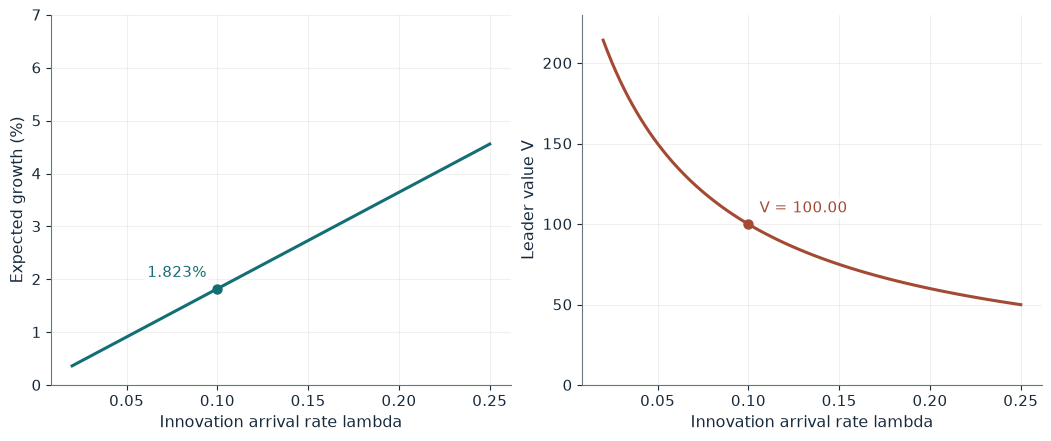

ln(gamma)                   0.182322
Expected growth             1.823%
Leader value V              100.00
Change in V vs lambda 0.10  0.00

Worked steps:
  1. ln(1.20) = 0.182322
  2. g = 0.10 x 0.182322 = 0.018232
  3. r + lambda = 0.05 + 0.10 = 0.15
  4. V = 15 / 0.15 = 100.00

Growth = 0.10 x ln(1.20) = 0.10 x 0.182322 = 0.018232, or 1.823 percent a year. The leader's value is 15 / (0.05 + 0.10) = 100.00. Faster entry raises growth and shortens each leadership spell; the quality step changes growth but not V.


In [4]:
show(ladder_picture(lam=0.10, gamma=1.20))

Change one input, `lam`, and hold the others at the book's values:

In [5]:
sweep(ladder_picture, 'lam', [0.05, 0.1, 0.15, 0.2], {'gamma': 1.2}, ['Expected growth', 'Leader value V'])

lam | Expected growth | Leader value V
0.05 | 0.912% | 150.00
0.1 | 1.823% | 100.00
0.15 | 2.735% | 75.00
0.2 | 3.646% | 60.00


At $\lambda=0.15$ growth rises to 2.735 percent but the leader's value falls to 75: faster entry speeds growth and shortens every leadership spell.

## 3. O-ring production: weakest link teams

Two-task teams with $Bn=120$; two workers of quality 0.90 and two of quality 0.60.

$$120(0.90)(0.60)=64.8, \qquad 120(0.90)^2=97.2, \qquad 140.4-129.6=10.8$$

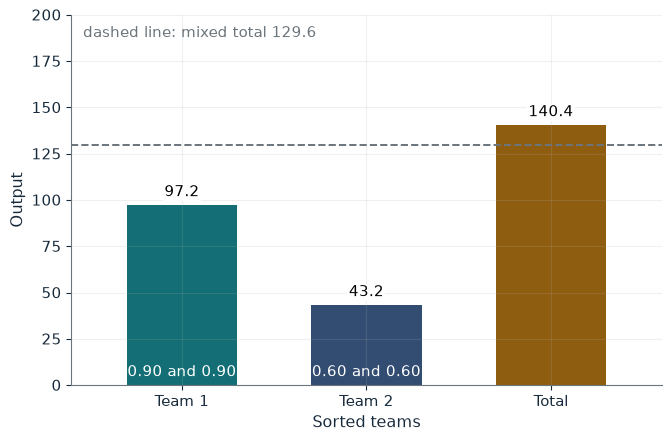

Mixed total                129.6
Sorted total               140.4
Sorting gain               10.8
Training gain beside 0.90  16.2
Training gain beside 0.60  10.8

Worked steps:
  1. Mixed team = 120 x 0.90 x 0.60 = 64.8; two teams = 129.6
  2. Sorted = 97.2 + 43.2 = 140.4
  3. Gain = 140.4 - 129.6 = 10.8 = 120 x 0.30^2
  4. Training: 120 x 0.90 x 0.15 = 16.2; 120 x 0.60 x 0.15 = 10.8

Mixed: 2 x 120 x 0.90 x 0.60 = 129.6. Sorted: 120 x 0.90^2 + 120 x 0.60^2 = 97.2 + 43.2 = 140.4. The gain from sorting is 120 x (0.90 - 0.60)^2 = 10.8 with no change in any skill. Raising a 0.60 worker by 0.15 adds 16.2 beside a 0.90 partner and 10.8 beside a 0.60 partner.


In [6]:
show(oring_picture(l=0.60, match='sorted'))

Change one input, `l`, and hold the others at the book's values:

In [7]:
sweep(oring_picture, 'l', [0.45, 0.6, 0.75], {'match': 'sorted'}, ['Mixed total', 'Sorted total', 'Sorting gain'])

l | Mixed total | Sorted total | Sorting gain
0.45 | 97.2 | 121.5 | 24.3
0.6 | 129.6 | 140.4 | 10.8
0.75 | 162.0 | 164.7 | 2.7


Sorting gains $Bn(h-l)^2$ with no change in skill, and the same 0.15 training upgrade adds 16.2 beside a 0.90 partner but only 10.8 beside a 0.60 partner.

## 4. AK growth: saving that raises growth forever

$y=0.25k$, depreciation 3.5 percent, population growth 0.5 percent, $y_0=50$.

$$g_y'=(0.30)(0.25)-0.035-0.005=0.035, \qquad y_{10}'=50e^{0.035(10)}=50e^{0.35}\approx70.95$$

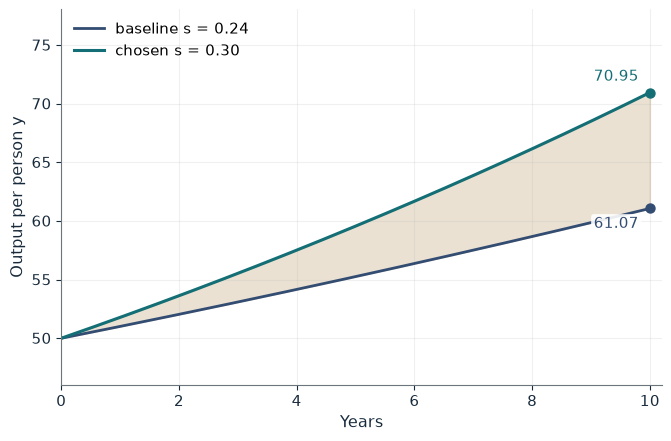

Growth at chosen s           3.5%
Baseline growth              2.0%
y at year 10                 70.95
Baseline y                   61.07
Gap                          9.88
Net accumulation at k = 200  7.00

Worked steps:
  1. g = 0.30 x 0.25 - 0.035 - 0.005 = 0.0350
  2. Investment at k = 200: 0.30 x 50 = 15.00; net = 15.00 - 7 - 1 = 7.00
  3. y_T = 50 e^(0.3500) = 70.95
  4. Baseline y_T = 50 e^(0.2000) = 61.07
  5. Gap = 70.95 - 61.07 = 9.88

g = 0.30 x 0.25 - 0.035 - 0.005 = 0.0350. Starting from y0 = 50, y at year 10 is 50 e^(0.0350 x 10) = 70.95 against a baseline 50 e^(0.02 x 10) = 61.07, a gap of 9.88. At k = 200 net accumulation is 15.00 - 7 - 1 = 7.00. The gap keeps widening because the growth difference never shrinks in the AK model.


In [8]:
show(ak_picture(s=0.30, years=10))

Change one input, `years`, and hold the others at the book's values:

In [9]:
sweep(ak_picture, 'years', [10, 20, 40], {'s': 0.3}, ['Baseline y', 'Gap'])

years | Baseline y | Gap
10 | 61.07 | 9.88
20 | 74.59 | 26.10
40 | 111.28 | 91.48


The gap of 9.88 at ten years keeps widening, because the growth difference never shrinks when returns to capital do not diminish.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

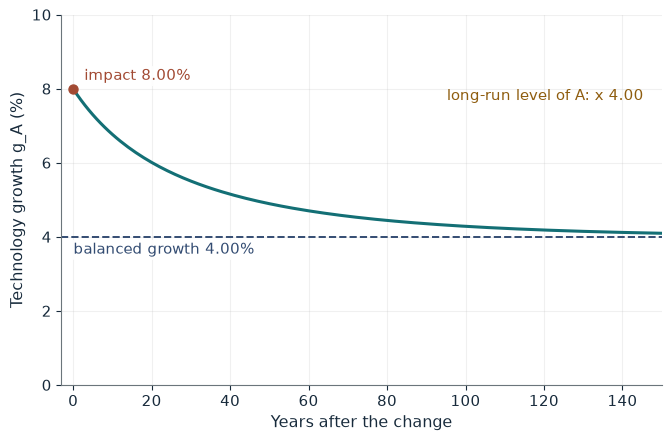

Research labor L_A            288
delta                         0.025
Impact g_A                    8.00%
Balanced g*                   4.00%
Long-run level multiple of A  4.00

Worked steps:
  1. g* = lambda n / (1 - phi) = 0.02 / 0.50 = 0.0400
  2. delta = g* x 8,100^0.50 / 144 = 0.040000 x 90.00 / 144 = 0.025000
  3. Impact g_A = 0.025000 x 288 / 90.00 = 0.0800
  4. Level multiple = 2^(1 / 0.50) = 4.00

g* = 1 x 0.02 / (1 - 0.50) = 0.0400. With delta = 0.025000 the old path is balanced, and at A = 8,100 the impact rate is 0.025000 x 288 / 90.00 = 0.0800. The level multiple is 2^(1 / 0.50) = 4.00. Growth jumps to 8.00% and then decays back to 4.00%: the 2-fold research effort buys a permanently higher level, not faster long-run growth.


In [10]:
show(semi_picture(mult=2, phi=0.5))

## Practice

**1.** With phi = 0.75 and research labor doubled, what is the long-run level multiple of A and the balanced rate?

<details><summary>Answer</summary>

2^(1 / 0.25) = 16; g* = 0.02 / 0.25 = 0.08.

</details>

**2.** With low quality l = 0.45 and Bn = 120, what is the gain from sorting?

<details><summary>Answer</summary>

120 x (0.90 - 0.45)^2 = 120 x 0.2025 = 24.3.

</details>

**3.** At s = 0.30 and k = 200, what is net accumulation and its share of capital?

<details><summary>Answer</summary>

0.30 x 50 - 7 - 1 = 7, which is 7 / 200 = 3.5 percent.

</details>